# 03 - Model Evaluation
Held-out test set (114 samples, 42 malignant). Run `python -m src.train` first.

In [1]:
import sys; sys.path.append('..')
import warnings; warnings.filterwarnings('ignore')
%matplotlib inline
import matplotlib.pyplot as plt, pandas as pd, numpy as np
from src.data_loader import load_data, split_data
from sklearn.metrics import confusion_matrix, brier_score_loss
from src.evaluate import load_model, false_negatives
model, meta = load_model()
X, y = load_data()
X_train, X_test, y_train, y_test = split_data(X, y)
p = model.predict_proba(X_test)[:,1]
print(meta['model'], '| tuned threshold', round(meta['threshold'],3))

Logistic Regression | tuned threshold 0.284


## Model comparison (test set)

In [2]:
pd.read_csv('../reports/model_comparison.csv').set_index('model')[['cv_pr_auc','test_pr_auc','test_roc_auc','FN@0.5','FP@0.5','FN@tuned','FP@tuned']]

,cv_pr_auc,test_pr_auc,test_roc_auc,FN@0.5,FP@0.5,FN@tuned,FP@tuned
model,,,,,,,
Logistic Regression,0.9941,0.9931,0.9954,2,1,2,2
Random Forest,0.9878,0.9952,0.9970,4,0,1,4
Gradient Boosting,0.9893,0.9920,0.9947,4,0,3,2


## Confusion matrices

In [3]:
for t in [0.5, meta['threshold']]:
    tn, fp, fn, tp = confusion_matrix(y_test, (p>=t).astype(int)).ravel()
    print(f'threshold {t:.3f}:  TP={tp} FN={fn} FP={fp} TN={tn}  recall={tp/(tp+fn):.3f} precision={tp/(tp+fp):.3f}')

threshold 0.500:  TP=40 FN=2 FP=1 TN=71  recall=0.952 precision=0.976
threshold 0.284:  TP=40 FN=2 FP=2 TN=70  recall=0.952 precision=0.952


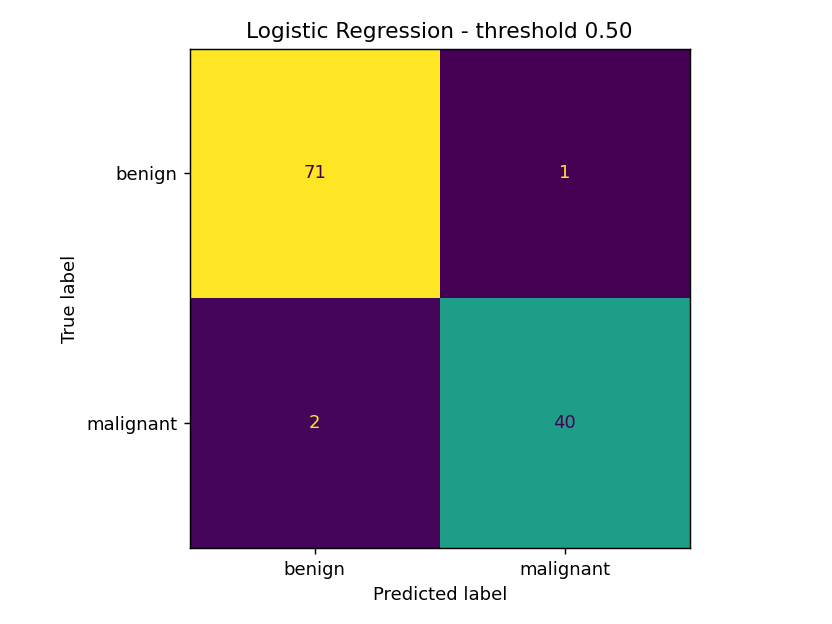

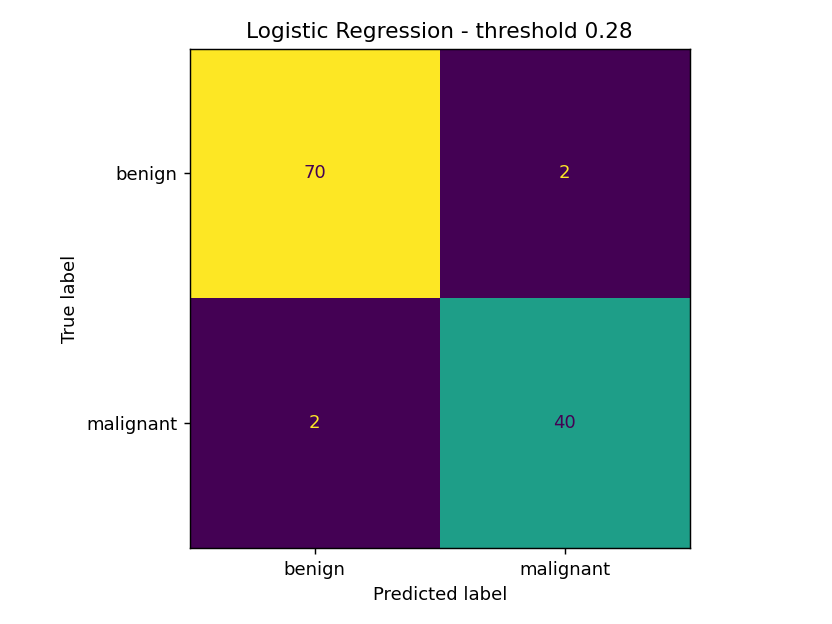

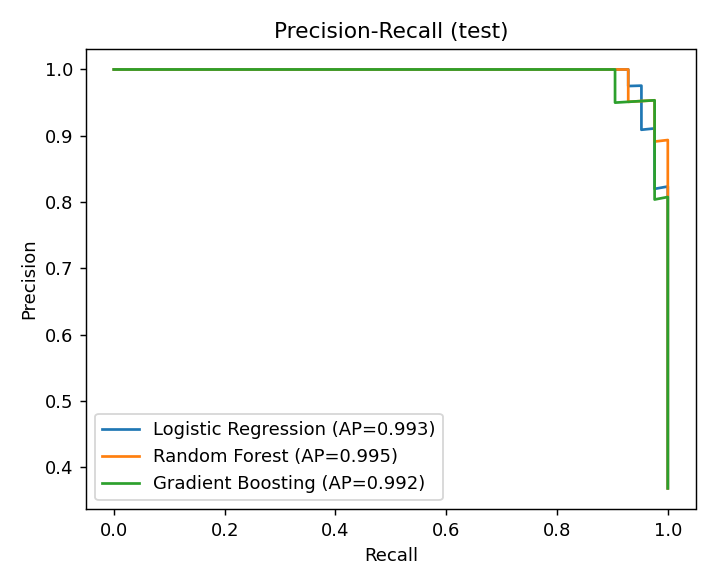

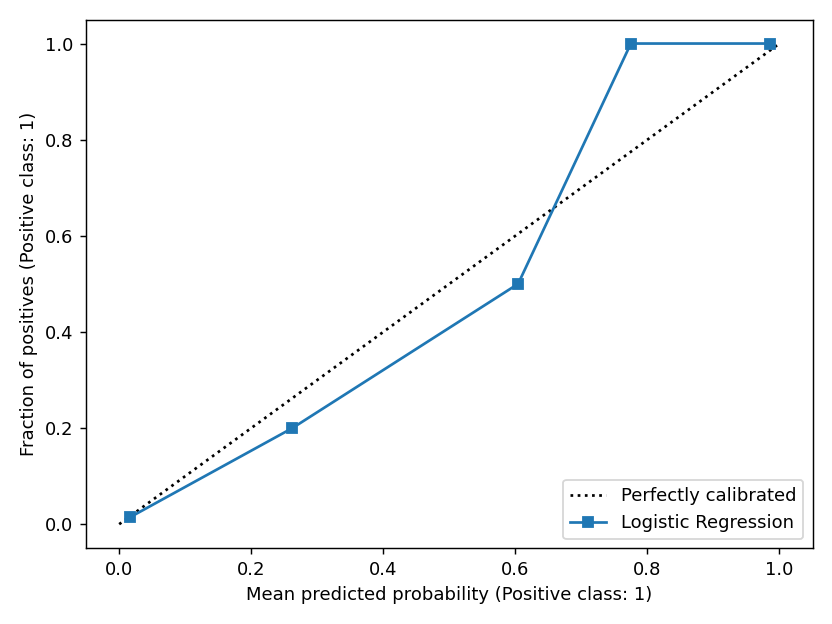

In [4]:
from IPython.display import Image, display
for f in ['confusion_matrix_default_0.5','confusion_matrix_tuned','pr_curves_all_models','calibration']:
    display(Image(f'../reports/figures/{f}.png', width=420))

## False-negative analysis
Missed malignant cases at the default threshold, and which features deviate most from the typical malignant profile.

In [5]:
fn = false_negatives(model, X_test, y_test, X_train, y_train, 0.5)
fn

,sample,malignant_probability,most_atypical_features
0,73,0.088,"worst texture, mean texture, texture error"
1,190,0.274,"compactness error, fractal dimension error, co..."


## Limitations
- Only 42 malignant test cases: one missed case moves recall by ~2.4 points, so model differences are within noise.
- Single dataset from one source; no external validation.
- Tuning the threshold did not reduce false negatives for the selected model on this split, only raised false positives. Gains for other models (e.g. Random Forest 4 to 1 FN) should not be over-read.
- Features are lab-extracted measurements, not images; results do not transfer to image-based or other-site data.
- Not a clinically validated diagnostic system.